# 11 — Bolsões e top 1% **por plataforma**

Mesmo método do notebook 10, rodado **dentro** de cada plataforma: o top 5% e o top 1% são recalculados por plataforma, e a própria plataforma não entra como atributo.
Evidência: **robusta** (FDR na tabela da plataforma; marcamos também a correção **global**, somando as 15 tabelas) · **replicada** (nas 2 metades do período) · **exploratória** (p < 0,05).
Cada plataforma tem ~10 mil posts, um quinto da base, então os testes têm menos poder que no notebook 10.

In [1]:
# Setup: make solution/src importable and load the posts with derived features.
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "solution" / "src").exists())
sys.path.insert(0, str(ROOT / "solution" / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from social_insights import data, top_performers as tp, clustering as cl, drivers as dr, audience as au, nlp, validation as va, plots

plots.apply_style()
pd.set_option("display.float_format", "{:.4f}".format)
df = data.load_posts(ROOT)
print(f"{len(df):,} posts")

from scipy import stats
from statsmodels.stats.multitest import multipletests
from social_insights import discovery as dv
METRICS = ["views", "likes", "comments_count"]
PLATFORMS = data.PLATFORMS
T = pd.concat([dv.scan_by_platform(df, m, platforms=PLATFORMS) for m in METRICS], ignore_index=True)
T["q_global"] = multipletests(T["p_value"], method="fdr_bh")[1]
summary = dv.platform_summary(T)
summary[["bolsões testados", "p<0,05 nos dados completos", "esperado por acaso", "descobertos na 1ª metade", "replicaram na 2ª metade",
         "taxa de replicação (%)", "p (replicação acima do acaso)", "robustos (FDR)"]].round(3)

52,214 posts


bolsões testados  p<0,05 nos dados completos  \
plataforma alvo                                                           
Bilibili   comments_count          994.0000                     59.0000   
           likes                   994.0000                     31.0000   
           views                   994.0000                     72.0000   
Instagram  comments_count          981.0000                     66.0000   
           likes                   981.0000                     60.0000   
           views                   981.0000                     35.0000   
RedNote    comments_count          984.0000                     43.0000   
           likes                   984.0000                     44.0000   
           views                   984.0000                     38.0000   
TikTok     comments_count          979.0000                     51.0000   
           likes                   979.0000                     40.0000   
           views                   979.0000                     59.0000   
YouTube    comments_count          983.0000                     35.0000   
           likes                   983.0000                     33.0000   
           views                   983.0000                     36.0000   

                           esperado por acaso  descobertos na 1ª metade  \
plataforma alvo                                                           
Bilibili   comments_count             50.0000                   50.0000   
           likes                      50.0000                   50.0000   
           views                      50.0000                   51.0000   
Instagram  comments_count             49.0000                   41.0000   
           likes                      49.0000                   57.0000   
           views                      49.0000                   46.0000   
RedNote    comments_count             49.0000                   43.0000   
           likes                      49.0000                   42.0000   
           views                      49.0000                   57.0000   
TikTok     comments_count             49.0000                   48.0000   
           likes                      49.0000                   48.0000   
           views                      49.0000                   53.0000   
YouTube    comments_count             49.0000                   41.0000   
           likes                      49.0000                   34.0000   
           views                      49.0000                   32.0000   

                           replicaram na 2ª metade  taxa de replicação (%)  \
plataforma alvo                                                              
Bilibili   comments_count                   2.0000                  4.0000   
           likes                            0.0000                  0.0000   
           views                            4.0000                  7.8430   
Instagram  comments_count                   2.0000                  4.8780   
           likes                            2.0000                  3.5090   
           views                            0.0000                  0.0000   
RedNote    comments_count                   3.0000                  6.9770   
           likes                            1.0000                  2.3810   
           views                            1.0000                  1.7540   
TikTok     comments_count                   3.0000                  6.2500   
           likes                            3.0000                  6.2500   
           views                            4.0000                  7.5470   
YouTube    comments_count                   2.0000                  4.8780   
           likes                            0.0000                  0.0000   
           views                            4.0000                 12.5000   

                           p (replicação acima do acaso)  robustos (FDR)  
plataforma alvo                                                          

## 1. Panorama: quantos insights replicados/robustos em cada plataforma?

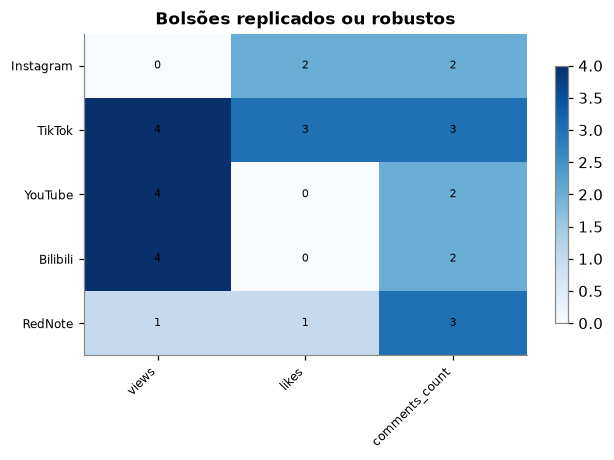

**Total:** 31 bolsões replicados ou robustos · robustos na tabela da plataforma: 1 · robustos na correção global (15 tabelas, 14,763 testes): 1

In [2]:
strong = T[T["evidência"].isin(["robusta (FDR)", "replicada (2 metades)"])]
counts = strong.pivot_table(index="plataforma", columns="alvo", values="bolsão", aggfunc="count", fill_value=0).reindex(index=PLATFORMS, columns=METRICS, fill_value=0)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
plots.heatmap(ax, counts.astype(float), "Bolsões replicados ou robustos", cmap="Blues", vmin=0, fmt="{:.0f}")
plt.show()
display(Markdown(f"**Total:** {len(strong)} bolsões replicados ou robustos · robustos na tabela da plataforma: {int((T['evidência'] == 'robusta (FDR)').sum())} · "
                 f"robustos na correção global (15 tabelas, {len(T):,} testes): {int((T['q_global'] < 0.05).sum())}"))

## 2. ⭐ Destaque robusto: TikTok · beauty em espanhol → likes

**10.0%** dos 451 posts chegam ao top 5% de likes do TikTok (**2.02x**). 1ª metade 2.23x · 2ª metade 1.83x · q (TikTok) = 0.002 · q (global) = 0.035

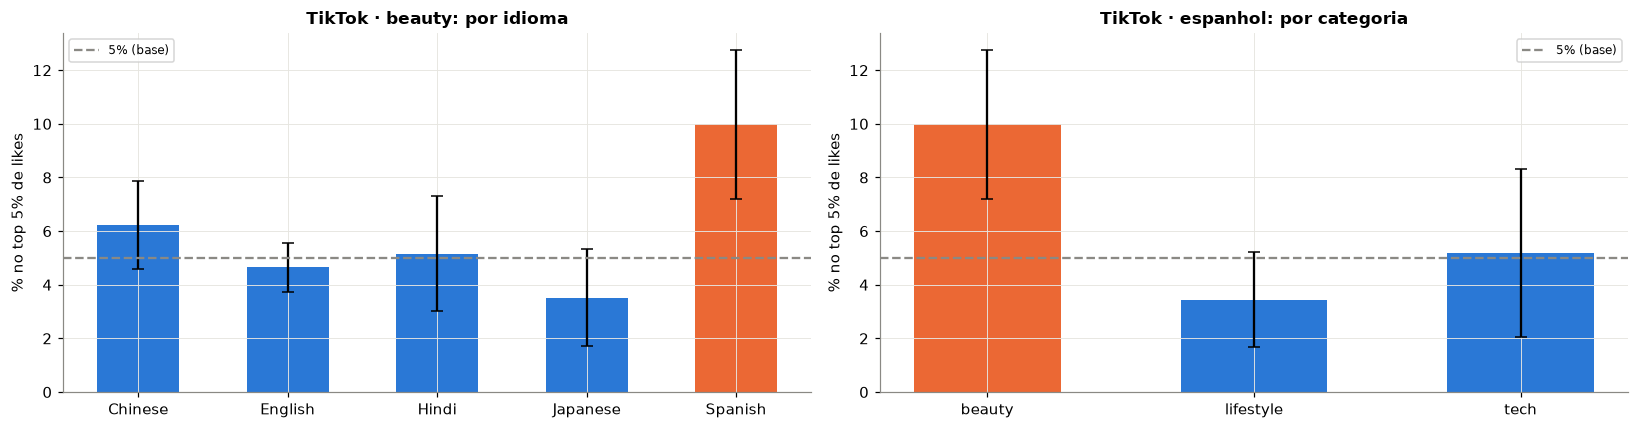

Média de likes: 1,516.2 vs. 1,510.3 no resto do TikTok

In [3]:
tk = df[df.platform == "TikTok"].copy()
tk["top5_likes"] = tk.likes >= tk.likes.quantile(0.95)
row = T[(T.plataforma == "TikTok") & (T.alvo == "likes") & (T["bolsão"] == "beauty · Spanish")].iloc[0]
display(Markdown(f"**{row['taxa top 5% (%)']:.1f}%** dos {row['posts']} posts chegam ao top 5% de likes do TikTok (**{row['lift']:.2f}x**). "
                 f"1ª metade {row['lift 1ª metade']:.2f}x · 2ª metade {row['lift 2ª metade']:.2f}x · q (TikTok) = {row['q_value']:.3f} · q (global) = {row['q_global']:.3f}"))
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, (filt, by, title) in zip(axes, [(tk.content_category == "beauty", "language", "TikTok · beauty: por idioma"),
                                        (tk.language == "Spanish", "content_category", "TikTok · espanhol: por categoria")]):
    g = tk[filt].groupby(by)["top5_likes"].agg(["mean", "size"])
    g["ci"] = 1.96 * np.sqrt(g["mean"] * (1 - g["mean"]) / g["size"])
    ax.bar(g.index, g["mean"] * 100, yerr=g["ci"] * 100, color=[plots.ORANGE if i in ("Spanish", "beauty") else plots.BLUE for i in g.index],
           width=0.55, capsize=4)
    ax.axhline(5, color=plots.GRAY, linestyle="--", label="5% (base)"); ax.set_ylabel("% no top 5% de likes"); ax.set_title(title); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()
display(Markdown(f"Média de likes: {tk.loc[(tk.content_category == 'beauty') & (tk.language == 'Spanish'), 'likes'].mean():,.1f} vs. "
                 f"{tk.loc[~((tk.content_category == 'beauty') & (tk.language == 'Spanish')), 'likes'].mean():,.1f} no resto do TikTok"))

**Leitura:** é o **único achado de todo o projeto que sobrevive à correção global** (≈ 14,7 mil testes por plataforma, q ≈ 0,03), e ele **se repete nos dois anos**.
O efeito é na **cauda**: a média de likes quase não muda (+0,4%), mas a chance de um post bombar em likes **dobra**.
**Ação:** priorizar conteúdo de beauty em espanhol no TikTok e validar com teste A/B (ex.: versão em espanhol × inglês do mesmo conteúdo).

## 3. Insights replicados por plataforma

In [4]:
for p in PLATFORMS:
    sub = T[T.plataforma == p].sort_values(["evidência", "p_value"], ascending=[False, True])
    cards = pd.concat([dv.insight_cards(sub[sub.alvo == m], n=4) for m in METRICS], ignore_index=True)
    cards = cards[cards["evidência"] != "exploratória"] if (cards["evidência"] != "exploratória").any() else cards.head(3)
    display(Markdown(f"### {p}"))
    display(cards.style.hide(axis="index").set_properties(**{"text-align": "left"}))

### Instagram

evidência,insight,como validar
replicada (2 metades),"language × daypart = Japanese · tarde: 9.3% dos 227 posts chegam ao top 5% de likes (1.86x, mais que o resto). 1ª metade 1.87x · 2ª metade 1.84x · q = 0.74",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"language × follower_tier = Japanese · macro (100–500K): 8.0% dos 414 posts chegam ao top 5% de likes (1.61x, mais que o resto). 1ª metade 1.70x · 2ª metade 1.52x · q = 0.80",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"hour (janela) = 16–21: 3.8% dos 2,208 posts chegam ao top 5% de comentários (0.69x, menos que o resto). 1ª metade 0.66x · 2ª metade 0.72x · q = 0.42",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"audience_age_distribution × audience_location = 26-35 · Germany: 8.5% dos 389 posts chegam ao top 5% de comentários (1.71x, mais que o resto). 1ª metade 1.82x · 2ª metade 1.60x · q = 0.42",teste A/B ou acompanhamento nos próximos posts


### TikTok

evidência,insight,como validar
replicada (2 metades),"length_bin × weekday = longo (180–360) · Tuesday: 9.3% dos 354 posts chegam ao top 5% de views (1.91x, mais que o resto). 1ª metade 1.70x · 2ª metade 2.14x · q = 0.17",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"follower_tier × audience_age_distribution = macro (100–500K) · 19-25: 3.2% dos 1,470 posts chegam ao top 5% de views (0.60x, menos que o resto). 1ª metade 0.55x · 2ª metade 0.66x · q = 0.25",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"audience_age_distribution = 19-25: 4.1% dos 3,675 posts chegam ao top 5% de views (0.74x, menos que o resto). 1ª metade 0.71x · 2ª metade 0.77x · q = 0.40",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"length_bin × audience_age_distribution = médio (60–180) · 19-25: 3.4% dos 1,399 posts chegam ao top 5% de views (0.65x, menos que o resto). 1ª metade 0.61x · 2ª metade 0.69x · q = 0.45",teste A/B ou acompanhamento nos próximos posts
robusta (FDR),"content_category × language = beauty · Spanish: 10.0% dos 451 posts chegam ao top 5% de likes (2.02x, mais que o resto). 1ª metade 2.23x · 2ª metade 1.83x · q = 0.00",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"month = January: 7.9% dos 861 posts chegam ao top 5% de likes (1.61x, mais que o resto). 1ª metade 1.79x · 2ª metade 1.42x · q = 0.08",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"length_bin × daypart = muito longo (360+) · tarde: 7.7% dos 651 posts chegam ao top 5% de likes (1.54x, mais que o resto). 1ª metade 1.48x · 2ª metade 1.60x · q = 0.47",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"content_length (janela) = 174–316: 7.2% dos 2,054 posts chegam ao top 5% de comentários (1.37x, mais que o resto). 1ª metade 1.38x · 2ª metade 1.35x · q = 0.63",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"content_category × language = lifestyle · English: 7.1% dos 2,069 posts chegam ao top 5% de comentários (1.33x, mais que o resto). 1ª metade 1.34x · 2ª metade 1.32x · q = 0.63",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"language × weekday = English · Saturday: 8.1% dos 720 posts chegam ao top 5% de comentários (1.47x, mais que o resto). 1ª metade 1.54x · 2ª metade 1.41x · q = 0.65",teste A/B ou acompanhamento nos próximos posts


### YouTube

evidência,insight,como validar
replicada (2 metades),"content_category × length_bin = tech · longo (180–360): 8.1% dos 469 posts chegam ao top 5% de views (1.65x, mais que o resto). 1ª metade 1.81x · 2ª metade 1.50x · q = 0.51",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"content_category × follower_tier = tech · mega (500K+): 7.1% dos 986 posts chegam ao top 5% de views (1.46x, mais que o resto). 1ª metade 1.44x · 2ª metade 1.48x · q = 0.51",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"audience_gender_distribution × audience_location = male · Japan: 7.8% dos 536 posts chegam ao top 5% de views (1.60x, mais que o resto). 1ª metade 1.73x · 2ª metade 1.47x · q = 0.51",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"audience_gender_distribution × audience_location = female · Japan: 2.4% dos 506 posts chegam ao top 5% de views (0.46x, menos que o resto). 1ª metade 0.38x · 2ª metade 0.54x · q = 0.66",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"follower_tier × audience_location = macro (100–500K) · Brazil: 9.2% dos 511 posts chegam ao top 5% de comentários (1.72x, mais que o resto). 1ª metade 1.94x · 2ª metade 1.50x · q = 0.19",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"weekday × audience_gender_distribution = Saturday · female: 8.4% dos 606 posts chegam ao top 5% de comentários (1.57x, mais que o resto). 1ª metade 1.53x · 2ª metade 1.62x · q = 0.66",teste A/B ou acompanhamento nos próximos posts


### Bilibili

evidência,insight,como validar
replicada (2 metades),"language × follower_tier = Chinese · mega (500K+): 7.2% dos 1,092 posts chegam ao top 5% de views (1.51x, mais que o resto). 1ª metade 1.54x · 2ª metade 1.47x · q = 0.49",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"weekday × audience_age_distribution = Saturday · 13-18: 9.3% dos 236 posts chegam ao top 5% de views (1.88x, mais que o resto). 1ª metade 2.12x · 2ª metade 1.69x · q = 0.60",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"content_type × audience_location = video · Japan: 7.2% dos 814 posts chegam ao top 5% de views (1.49x, mais que o resto). 1ª metade 1.49x · 2ª metade 1.50x · q = 0.60",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"content_category × weekday = tech · Friday: 8.4% dos 311 posts chegam ao top 5% de views (1.69x, mais que o resto). 1ª metade 1.85x · 2ª metade 1.55x · q = 0.60",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"language = Hindi: 7.3% dos 1,080 posts chegam ao top 5% de comentários (1.47x, mais que o resto). 1ª metade 1.43x · 2ª metade 1.51x · q = 0.24",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"length_bin × weekday = médio (60–180) · Wednesday: 2.7% dos 556 posts chegam ao top 5% de comentários (0.50x, menos que o resto). 1ª metade 0.50x · 2ª metade 0.50x · q = 0.64",teste A/B ou acompanhamento nos próximos posts


### RedNote

evidência,insight,como validar
replicada (2 metades),"content_category × weekday = tech · Tuesday: 1.6% dos 312 posts chegam ao top 5% de views (0.31x, menos que o resto). 1ª metade 0.25x · 2ª metade 0.38x · q = 0.99",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"content_type × content_category = text · lifestyle: 8.2% dos 404 posts chegam ao top 5% de likes (1.58x, mais que o resto). 1ª metade 1.65x · 2ª metade 1.52x · q = 0.96",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"weekday × audience_gender_distribution = Thursday · female: 2.5% dos 565 posts chegam ao top 5% de comentários (0.43x, menos que o resto). 1ª metade 0.31x · 2ª metade 0.54x · q = 0.33",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"is_sponsored × weekday = False · Thursday: 3.1% dos 862 posts chegam ao top 5% de comentários (0.54x, menos que o resto). 1ª metade 0.53x · 2ª metade 0.55x · q = 0.33",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"length_bin × audience_location = médio (60–180) · India: 8.5% dos 515 posts chegam ao top 5% de comentários (1.56x, mais que o resto). 1ª metade 1.70x · 2ª metade 1.44x · q = 0.60",teste A/B ou acompanhamento nos próximos posts


## 4. Horário × comentários em cada plataforma

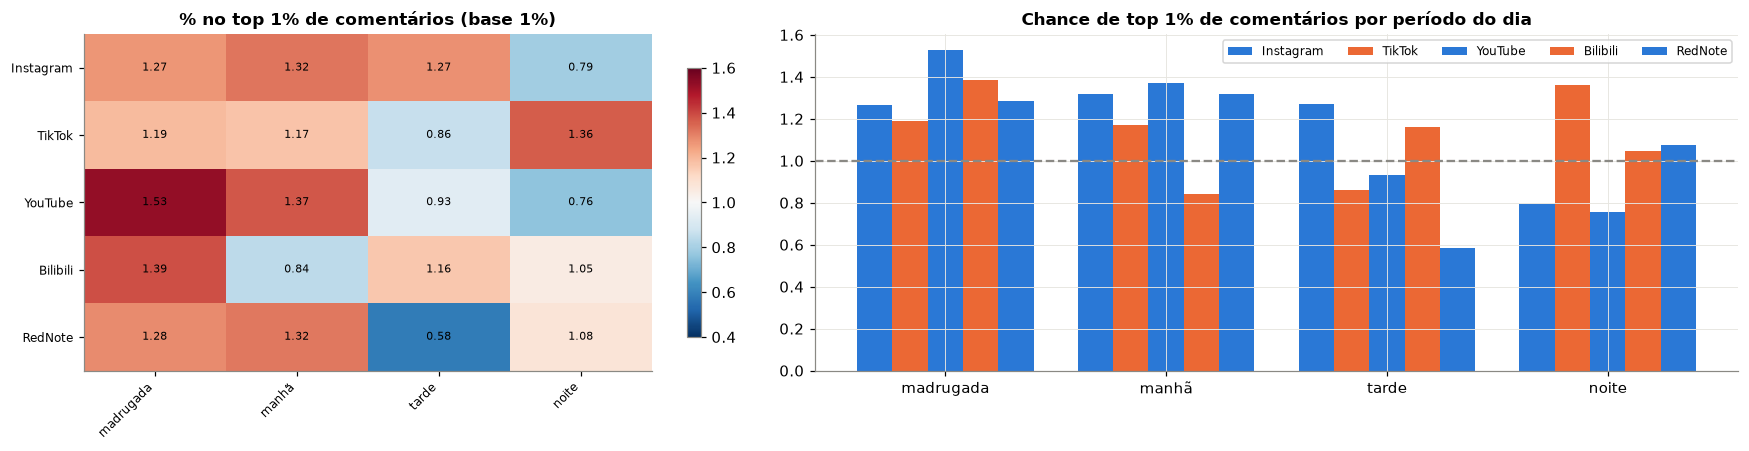

,madrugada,manhã,tarde,noite,p (qui²),hora mediana top,hora mediana demais,p (Mann-Whitney hora),q (hora)
platform,,,,,,,,,
Instagram,1.2660,1.3190,1.2730,0.7940,0.2400,11.0000,12.0000,0.2080,0.2610
TikTok,1.1900,1.1710,0.8600,1.3620,0.3970,11.0000,11.0000,0.9810,0.9810
YouTube,1.5270,1.3710,0.9340,0.7580,0.0290,9.0000,12.0000,0.0040,0.0190
Bilibili,1.3870,0.8440,1.1630,1.0480,0.2900,11.0000,11.0000,0.1740,0.2610
RedNote,1.2840,1.3180,0.5830,1.0760,0.0380,8.0000,11.0000,0.1220,0.2610


**YouTube por metade do período:**

,metade,hora mediana top,hora mediana demais,p,posts top
0,1ª,7.5000,12.0000,0.0440,56
1,2ª,10.0000,12.0000,0.0340,64


In [5]:
dp = dv.daypart_top_rate(df, "comments_count").reindex(PLATFORMS)
order = ["madrugada", "manhã", "tarde", "noite"]
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})
plots.heatmap(axes[0], dp[order], "% no top 1% de comentários (base 1%)", cmap="RdBu_r", vmin=0.4, vmax=1.6, fmt="{:.2f}")
x = np.arange(len(order)); w = 0.16
for i, p in enumerate(PLATFORMS):
    axes[1].bar(x + (i - 2) * w, dp.loc[p, order], width=w, label=p)
axes[1].axhline(1, color=plots.GRAY, linestyle="--"); axes[1].set_xticks(x, order); axes[1].legend(fontsize=8, ncol=5)
axes[1].set_title("Chance de top 1% de comentários por período do dia")
fig.tight_layout(); plt.show()
yt = df[df.platform == "YouTube"]; top = yt.comments_count >= yt.comments_count.quantile(0.99); half = yt.post_date < yt.post_date.median()
halves = [{"metade": n, "hora mediana top": yt.loc[top & h, "hour"].median(), "hora mediana demais": yt.loc[~top & h, "hour"].median(),
           "p": stats.mannwhitneyu(yt.loc[top & h, "hour"], yt.loc[~top & h, "hour"]).pvalue, "posts top": int((top & h).sum())}
          for n, h in [("1ª", half), ("2ª", ~half)]]
display(dp.round(3))
display(Markdown("**YouTube por metade do período:**")); display(pd.DataFrame(halves).round(3))

**Leitura:** o insight geral "postar cedo → mais posts no top 1% de comentários" vem principalmente do **YouTube**.
Lá, o top 1% sai às **9h** na mediana contra 12h (q ≈ 0,02), com madrugada 1,53% e manhã 1,37% contra noite 0,76%, e **se repete nos dois anos**.
No **RedNote**, a tarde é fraca (0,58%; qui² p = 0,04). Instagram e Bilibili seguem a mesma direção, sem significância.
No **TikTok**, não há padrão: a noite é até a melhor faixa (1,36%). **A recomendação de horário deve ser por plataforma.**

## 5. Top 1% por plataforma: semelhanças antes da postagem

In [6]:
rows, sims = [], []
for p in PLATFORMS:
    sub = df[df.platform == p].reset_index(drop=True)
    for m in METRICS:
        top = dv.top_mask(sub, m)
        prof = dv.top_numeric_profile(sub, m).reset_index().assign(plataforma=p, alvo=m)
        rows.append(prof)
        sim = dv.similarity_test(sub, top, draws=100)
        conc = dv.creator_concentration(sub, top, draws=100)
        sims.append({"plataforma": p, "alvo": m, "posts top": int(top.sum()), "similaridade top (%)": sim["similaridade média no top (%)"],
                     "similaridade sorteios (%)": sim["similaridade em sorteios (%)"], "p similaridade": sim["p_value"],
                     "creators ≥2 no top": conc["creators com ≥2 posts no top"], "esperado": conc["esperado por acaso"], "p creators": conc["p_value"]})
numeric = pd.concat(rows, ignore_index=True)
numeric["q (60 testes)"] = multipletests(numeric["p_value"], method="fdr_bh")[1]
display(Markdown("**Variáveis numéricas mais diferentes no top 1% (menor p):**"))
display(numeric.sort_values("p_value").head(8)[["plataforma", "alvo", "variável", "mediana top 1%", "mediana demais", "efeito (rank-biserial)",
                                                "p_value", "p 1ª metade", "p 2ª metade", "q (60 testes)"]].round(3))
display(Markdown("**O top 1% de cada plataforma é mais parecido entre si do que conjuntos sorteados? Concentra-se em poucos creators?**"))
pd.DataFrame(sims).set_index(["plataforma", "alvo"]).round(3)

**Variáveis numéricas mais diferentes no top 1% (menor p):**

,plataforma,alvo,variável,mediana top 1%,mediana demais,efeito (rank-biserial),p_value,p 1ª metade,p 2ª metade,q (60 testes)
16,TikTok,likes,content_length,132.0000,175.0000,-0.1720,0.0030,0.0930,0.0090,0.1120
34,YouTube,comments_count,hour,9.0000,12.0000,-0.1540,0.0040,0.0440,0.0340,0.1120
57,RedNote,comments_count,follower_count,413110.0000,503200.0000,-0.1280,0.0200,0.0300,0.2550,0.3230
26,YouTube,views,hour,9.0000,12.0000,-0.1300,0.0220,0.1020,0.1100,0.3230
2,Instagram,views,hour,9.5000,12.0000,-0.1180,0.0340,0.6160,0.0150,0.4090
0,Instagram,views,content_length,206.0000,169.0000,0.1120,0.0450,0.8850,0.0080,0.4210
36,Bilibili,views,content_length,146.0000,175.0000,-0.1070,0.0560,0.0300,0.5880,0.4210
7,Instagram,likes,caption_words,20.0000,18.0000,0.1070,0.0560,0.8120,0.0180,0.4210


**O top 1% de cada plataforma é mais parecido entre si do que conjuntos sorteados? Concentra-se em poucos creators?**

posts top  similaridade top (%)  \
plataforma alvo                                              
Instagram  views                 108               34.8460   
           likes                 108               34.9480   
           comments_count        121               35.7250   
TikTok     views                 103               32.9950   
           likes                 103               34.0700   
           comments_count        118               33.5050   
YouTube    views                 105               34.3970   
           likes                 108               36.1820   
           comments_count        120               35.3350   
Bilibili   views                 107               34.5210   
           likes                 108               34.5440   
           comments_count        118               34.7180   
RedNote    views                 106               35.1090   
           likes                 105               32.9910   
           comments_count        111               33.9160   

                           similaridade sorteios (%)  p similaridade  \
plataforma alvo                                                        
Instagram  views                             34.6450          0.3960   
           likes                             34.6450          0.3760   
           comments_count                    34.5220          0.1190   
TikTok     views                             34.3780          0.9700   
           likes                             34.3780          0.6440   
           comments_count                    34.1390          0.8020   
YouTube    views                             34.2730          0.4360   
           likes                             34.2510          0.0400   
           comments_count                    34.3550          0.1680   
Bilibili   views                             34.4560          0.4550   
           likes                             34.4630          0.4360   
           comments_count                    34.4190          0.3660   
RedNote    views                             34.1510          0.1490   
           likes                             34.2320          0.9500   
           comments_count                    34.2430          0.6440   

                           creators ≥2 no top  esperado  p creators  
plataforma alvo                                                      
Instagram  views                            2    1.1900      0.3070  
           likes                            0    1.1900      1.0000  
           comments_count                   1    1.4600      0.8320  
TikTok     views                            0    1.0500      1.0000  
           likes                            3    1.0500      0.1090  
           comments_count                   1    1.1800      0.6830  
YouTube    views                            1    1.1000      0.6730  
           likes                            0    1.1900      1.0000  
           comments_count                   2    1.3000      0.3660  
Bilibili   views                            1    0.9900      0.6440  
           likes                            0    0.9100      1.0000  
           comments_count                   2    1.0100      0.2770  
RedNote    views                            3    1.3400      0.1680  
           likes                            2    1.0600      0.2970  
           comments_count                   1    0.9500      0.5840

**Leitura:**
- **Semelhança:** em 14 de 15 combinações (plataforma × métrica), o top 1% é tão diverso quanto conjuntos sorteados. A exceção é **YouTube · likes**: 36,2% de atributos em comum vs. 34,3% (p = 0,04). Em 15 testes, ~1 assim é esperado por acaso, então fica como pista exploratória. Não há creators campeões em nenhuma plataforma.
- **Pistas numéricas no top 1% (antes de postar):**
  - **TikTok · likes:** posts **mais curtos** (duração mediana 132 vs. 175; p = 0,003; 2ª metade p = 0,009, 1ª p = 0,09), o que é quase replicado.
  - **YouTube · comentários:** postados mais cedo (9h vs. 12h), replicado nas 2 metades.
  - **YouTube e Instagram · views:** postados mais cedo (9h–9h30 vs. 12h; p = 0,02–0,03), mas não replicado.
  - Nessa família ampla (60 testes), nenhuma passa de q < 0,05 (melhores q ≈ 0,11). Ou seja, são **hipóteses priorizadas**.

## 6. Resumo por plataforma (para o time)
| Plataforma | Insight mais forte | Evidência | Ação |
|---|---|---|---|
| **TikTok** | beauty em espanhol → 2x mais chance de top 5% de likes | **robusta** (q global 0,03) + replicada | priorizar e testar A/B |
| **TikTok** | top 1% de likes com vídeos mais curtos (~130 vs. 175) | quase replicada | testar versões mais curtas |
| **YouTube** | top 1% de comentários sai às 9h na mediana (madrugada/manhã) | replicada + q 0,02 | publicar conteúdo de conversa antes do meio-dia |
| **YouTube** | tech com vídeo longo (180–360 s) ou creator mega → mais top 5% de views (1,5–1,6x) | replicada | teste A/B |
| **Bilibili** | hindi → 1,5x mais top 5% de comentários; chinês × creator mega → 1,5x views | replicada | teste A/B |
| **Instagram** | 16h–21h → 0,69x no top 5% de comentários; japonês → mais likes | replicada | evitar fim de tarde para posts de conversa |
| **RedNote** | tarde fraca para comentários (0,58x top 1%); texto × lifestyle → 1,6x likes | replicada / exploratória | testar horário |

**Cautela:** fora o destaque do TikTok, a taxa de replicação por plataforma fica perto do acaso (~5%). Os demais itens são hipóteses priorizadas, e o teste A/B decide.